# Wordplay, Metaphor, and Song Popularity: Data and Features
**Team JB: Jade Hao & Bhavi Kenia** | NLP Project Update 2

**Dataset:** [5 Million Song Lyrics (Kaggle)](https://www.kaggle.com/datasets/nikhilnayak123/5-million-song-lyrics-dataset)

This notebook covers: loading and filtering, cleaning and exploring, theme assignment, the balanced sample for annotation, and the linguistic features for Experiment 2.

## Imports and Configs for this Project

In [3]:
import os, re, glob, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)

#configurations
RANDOM_STATE= 42
GENRES= {"rap": "hip-hop/rap", "pop": "pop", "country": "country"}  # dataset tag -> display name
YEAR_MIN, YEAR_MAX = 1990, 2022
SAMPLE_FRAC    = 0.05     # fraction of matching rows kept per chunk (the full CSV is huge)
MIN_WORDS, MAX_WORDS = 80, 1200
MAX_SONGS_FOR_FEATURES = 20000   # cap for the slower feature extraction
N_PER_CELL= 20# songs per genre x theme cell for manual annotation
CSV_PATH= os.environ.get("LYRICS_CSV")
np.random.seed(RANDOM_STATE)

## Loading in the data
The full dataset is several GB, so this was read in chunks, keep only the three genres and year range

In [4]:
CSV_PATH = None

if CSV_PATH is None:
    import kagglehub
    folder = kagglehub.dataset_download("nikhilnayak123/5-million-song-lyrics-dataset")
    print("Downloaded to:", folder)
    csvs = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    CSV_PATH = max(csvs, key=os.path.getsize)
print("Using:", CSV_PATH)

header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print("Columns in file:", header)

Downloaded to: /Users/jadehao/.cache/kagglehub/datasets/nikhilnayak123/5-million-song-lyrics-dataset/versions/3
Using: /Users/jadehao/.cache/kagglehub/datasets/nikhilnayak123/5-million-song-lyrics-dataset/versions/3/ds2.csv
Columns in file: ['title', 'tag', 'artist', 'year', 'views', 'features', 'lyrics', 'id']


In [5]:
#define columns we wanted
wanted = ["title", "tag", "artist", "year", "views", "features", "lyrics", "id", "language"]
use_cols = [c for c in wanted if c in header]

parts, rows_seen = [], 0 #make list to store filtered chunks and counter for rows
for chunk in pd.read_csv(CSV_PATH, usecols=use_cols, chunksize=200_000):
    rows_seen += len(chunk)
    chunk = chunk[chunk["tag"].isin(GENRES)] #keep rows in genres in GENRES
    chunk["year"] = pd.to_numeric(chunk["year"], errors="coerce")
    chunk = chunk[chunk["year"].between(YEAR_MIN, YEAR_MAX)]
    if "language" in chunk.columns:
        chunk = chunk[chunk["language"] == "en"]
    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE))
#results
df = pd.concat(parts, ignore_index=True)
print(f"Rows scanned: {rows_seen:,} | rows kept after filtering/sampling: {len(df):,}")
df.head()

Rows scanned: 5,913,411 | rows kept after filtering/sampling: 217,155


,title,tag,artist,year,views,features,lyrics,id
0,Blink of an Eye,rap,RUSSELL!,2011,1938,{},"[Hook: Pryde]\nFirst I started off small, now I've gone big\nNow I'm big doi...",51415
1,Paradise,rap,Najee The 1,2012,133,{DB2},[Intro: Najee]\nThe winner's over here\nYou're standing over there\nPut down...,80964
2,Hydraulicy,rap,BeST (PL),2016,968,{},"[Zwrotka 1]\nJebać leszczy, z lamusami się nie pieścić\nTrzygłowy potwór, bo...",212832
3,Schließ die Augen und vergiss,rap,Massiv,2012,1472,{},Wasiem Taha\nGeboren in einer kleinen Stadt\nUm genauer zu sein: 9.11.1982\n...,81128
4,Flows 4 The Jeep,rap,Darius Dossman,2013,50,{},[Verse 1: Darius]\nHolla at mr got the flows for the cheap\nThis shit can go...,117482


## Cleaning the lyrics

In [6]:
def clean_lyrics(t):
    if not isinstance(t, str):
        return ""
    t=re.sub(r"\[[^\]]*\]", "", t)# [Verse 1], [Chorus: Artist]
    t=re.sub(r"\d*Embed\s*$", "", t.strip())  # trailing 'Embed'
    t=re.sub(r"\n{2,}", "\n", t)
    return t.strip()

n0 = len(df)
df["lyrics_clean"] = df["lyrics"].apply(clean_lyrics)
df["n_words"] = df["lyrics_clean"].str.split().str.len()
df = df[df["n_words"].between(MIN_WORDS, MAX_WORDS)]
df = df.dropna(subset=["views", "artist", "title"])
df = df.drop_duplicates(subset=["title", "artist"]).drop_duplicates(subset="lyrics_clean")
df["genre"] = df["tag"].map(GENRES)
df["log_views"] = np.log1p(df["views"])
df["song_id"] = np.arange(len(df))
df = df.reset_index(drop=True)
print(f"{n0:,} -> {len(df):,} songs after cleaning")

217,155 -> 176,055 songs after cleaning


## Exploring the data

In [27]:
#look at shape of the data 
print(df.shape)
display(df[["genre", "year", "views", "n_words"]].describe().round(1))
display(df["genre"].value_counts().to_frame("songs"))

(176055, 16)


,year,views,n_words
count,176055.0,176055.0,176055.0
mean,2014.4,3481.2,314.4
std,7.2,52017.9,171.6
min,1990.0,0.0,80.0
25%,2012.0,25.0,183.0
50%,2017.0,91.0,277.0
75%,2020.0,457.0,409.0
max,2022.0,6893540.0,1199.0


,songs
genre,
pop,88919
hip-hop/rap,83330
country,3806


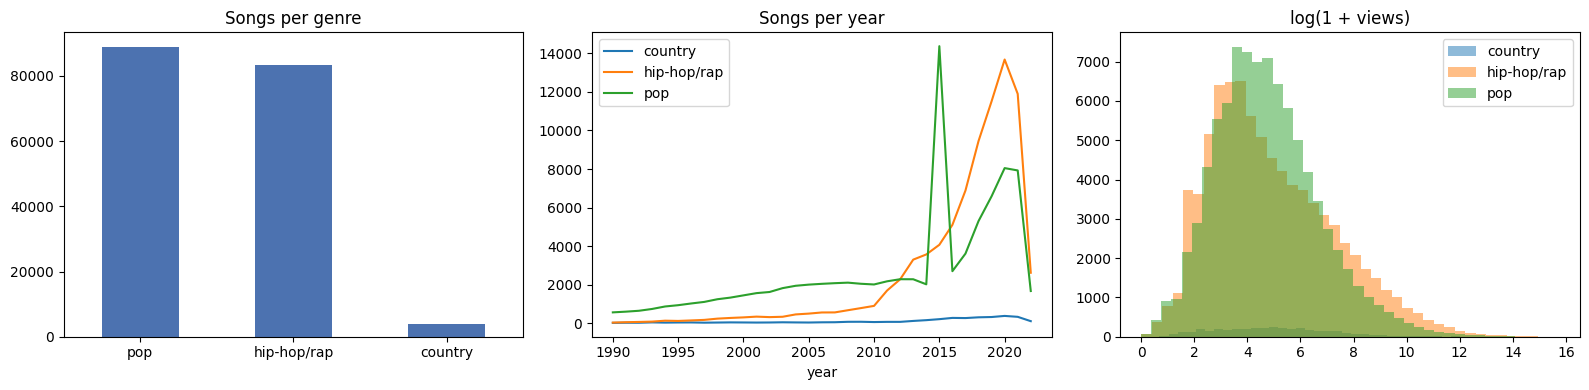

In [28]:
#create figure based on EDA above
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df["genre"].value_counts().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Songs per genre"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

for g, sub in df.groupby("genre"):
    sub["year"].value_counts().sort_index().plot(ax=ax[1], label=g)
ax[1].set_title("Songs per year"); ax[1].legend()

for g, sub in df.groupby("genre"):
    ax[2].hist(sub["log_views"], bins=40, alpha=0.5, label=g)
ax[2].set_title("log(1 + views)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [9]:
# views are heavily skewed and tied to song age/artist fame
print("Views skew (raw):     ", round(df["views"].skew(), 1))
print("Views skew (log):     ", round(df["log_views"].skew(), 2))
print("Corr(year, log_views):", round(df[["year", "log_views"]].corr().iloc[0, 1], 3))
display(df.groupby("genre")["log_views"].agg(["mean", "median", "std"]).round(2))

Views skew (raw):      60.5
Views skew (log):      0.7
Corr(year, log_views): -0.104


,mean,median,std
genre,,,
country,4.93,4.88,2.17
hip-hop/rap,4.91,4.45,2.34
pop,4.74,4.54,1.95


## Theme labeling --> (baseline)

In [10]:
LOVE_WORDS = {"love","loved","loving","lover","baby","babe","kiss","kisses","heart","hearts","darling",
              "girl","boy","miss","missing","forever","touch","hold","holding","romance","desire",
              "together","sweetheart","honey","boyfriend","girlfriend","wife","husband","marry","tonight"}
LOVE_PHRASES = ["fall in love", "falling in love", "miss you", "need you", "want you", "love you", "with you"]

STRUGGLE_WORDS = {"pain","struggle","struggling","hustle","grind","fight","fighting","scar","scars","broken",
                  "tears","cry","crying","alone","lonely","demons","survive","survived","lost","hurt",
                  "hurting","identity","mask","proud","myself","truth","real","poor","hungry","dream",
                  "dreams","doubt","fear","afraid","darkness","hell","fell","rise","risen"}
STRUGGLE_PHRASES = ["who i am", "my life", "all my life", "trying to", "come up", "never give up", "on my own"]

def theme_scores(text):
    low = text.lower()
    toks = re.findall(r"[a-z']+", low)
    n = max(len(toks), 1)
    love = sum(t in LOVE_WORDS for t in toks) + sum(low.count(p) for p in LOVE_PHRASES)
    strg = sum(t in STRUGGLE_WORDS for t in toks) + sum(low.count(p) for p in STRUGGLE_PHRASES)
    return pd.Series({"love_score": 100 * love / n, "struggle_score": 100 * strg / n})

df[["love_score", "struggle_score"]] = df["lyrics_clean"].apply(theme_scores)

MIN_SCORE, MIN_RATIO = 1.5, 1.5   # per-100-word score and dominance ratio
def assign_theme(r):
    l, s = r["love_score"], r["struggle_score"]
    if l >= MIN_SCORE and l >= MIN_RATIO * s: return "love/relationships"
    if s >= MIN_SCORE and s >= MIN_RATIO * l: return "struggle/identity"
    return "unassigned"

df["theme"] = df.apply(assign_theme, axis=1)
display(pd.crosstab(df["genre"], df["theme"]))

theme,love/relationships,struggle/identity,unassigned
genre,,,
country,1314,421,2071
hip-hop/rap,9879,5850,67601
pop,22662,10851,55406


In [11]:
#read a few auto-labeled songs per theme before fully trusting the labels :p
for theme in ["love/relationships", "struggle/identity"]:
    print("=" * 20, theme, "=" * 20)
    s = df[df["theme"] == theme].sample(3, random_state=1)
    for _, r in s.iterrows():
        print(f"[{r['genre']}] {r['title']} - {r['artist']} ({int(r['year'])})")
        print("   ", r["lyrics_clean"][:180].replace("\n", " / "), "...\n")

==================== love/relationships ====================
[hip-hop/rap] If We All Gone Fuck Live 1996 - 2Pac (2005)
    How y'all feel out there? / It's a whole lotta pretty motherfucking ladies in the crowd tonight / But you know what? / There's so many women and so less niggas / Let's all fuck / Get up to g ...

[hip-hop/rap] Заберу своё Ill take all my - PLUTOLOVE (2019)
    Нужно побольше swaga (swag) / Деньги  лишь бумага  (ага) / Заберу своё мне вашего дерьма не надо (нет) / Нужно побольше swaga (swag) / Деньги  лишь бумага  (ага) / Заберу своё мне вашего дер ...

[hip-hop/rap] 2Cozy - MAZHONE (2020)
    2 cozy / Baby, I‘m too cozy / Baby, I‘m too cozy / : / (2COZY)  So wie der Asap Mob.  / (2COZY)  Candyman im Candyshop / (2COZY )  Live Forever Zombie / Nobody can control me  / Im too cozy / Ich li ...

==================== struggle/identity ====================
[hip-hop/rap] Real Talk - KR (2017)
    It's almost like i'm (Miami) streets / I start a fire, Michael Myers / Then

## Balanced annotation sample

In [12]:
cells_df = df[df["theme"] != "unassigned"]
counts = cells_df.groupby(["genre", "theme"]).size()
print("Available per cell (min should be >= N_PER_CELL):"); display(counts.to_frame("available"))

pieces = []
for (g, t), grp in cells_df.groupby(["genre", "theme"]):
    s = grp.sample(min(len(grp), N_PER_CELL), random_state=RANDOM_STATE).copy()
    s["double_annotate"] = False
    k = max(1, int(round(0.2 * len(s))))# ~20% flagged for a second annotator, per cell
    s.loc[s.sample(k, random_state=RANDOM_STATE).index, "double_annotate"] = True
    pieces.append(s)
sample = pd.concat(pieces).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)  #shuffle so order doesn't reveal genre

for c in ["wordplay_count", "metaphor_count", "wordplay_examples", "metaphor_examples", "annotator"]:
    sample[c] = ""

annot_cols = ["song_id", "genre", "theme", "title", "artist", "year", "n_words", "double_annotate",
              "lyrics_clean", "wordplay_count", "metaphor_count", "wordplay_examples", "metaphor_examples", "annotator"]
sample[annot_cols].to_csv("annotation_sample.csv", index=False)
print(f"Saved annotation_sample.csv with {len(sample)} songs ({sample['double_annotate'].sum()} for double annotation)")

Available per cell (min should be >= N_PER_CELL):


available
genre       theme                        
country     love/relationships       1314
            struggle/identity         421
hip-hop/rap love/relationships       9879
            struggle/identity        5850
pop         love/relationships      22662
            struggle/identity       10851

Saved annotation_sample.csv with 120 songs (24 for double annotation)


### Analyze completed annotations

In [13]:
from scipy.stats import kruskal, spearmanr
from sklearn.metrics import cohen_kappa_score# use with per-line binary labels

def load_annotations(path):
    a = pd.read_csv(path)
    for c in ["wordplay_count", "metaphor_count"]:
        a[c] = pd.to_numeric(a[c], errors="coerce")
    a["wordplay_per_1k"] = 1000 * a["wordplay_count"] / a["n_words"]
    a["metaphor_per_1k"] = 1000 * a["metaphor_count"] / a["n_words"]
    return a

if os.path.exists("annotations_annotator1.csv"):
    a1 = load_annotations("annotations_annotator1.csv").dropna(subset=["wordplay_count", "metaphor_count"])
    print("Mean rates per 1,000 words by genre x theme:")
    display(a1.groupby(["genre", "theme"])[["wordplay_per_1k", "metaphor_per_1k"]].mean().round(2))

    for metric in ["wordplay_per_1k", "metaphor_per_1k"]:
        groups = [g[metric].values for _, g in a1.groupby("genre")]
        h, p = kruskal(*groups)
        print(f"Kruskal-Wallis across genres, {metric}: H={h:.2f}, p={p:.4f}")

    a1.groupby("genre")[["wordplay_per_1k", "metaphor_per_1k"]].mean().plot.bar(figsize=(7, 4))
    plt.title("Annotated rate per 1,000 words"); plt.xticks(rotation=0); plt.show()

    if os.path.exists("annotations_annotator2.csv"):
        a2 = load_annotations("annotations_annotator2.csv").dropna(subset=["wordplay_count", "metaphor_count"])
        m = a1.merge(a2, on="song_id", suffixes=("_1", "_2"))
        for c in ["wordplay_count", "metaphor_count"]:
            rho, p = spearmanr(m[c + "_1"], m[c + "_2"])
            print(f"Agreement on {c} (n={len(m)}): Spearman rho={rho:.2f} (p={p:.3f}), "
                  f"mean abs diff={np.abs(m[c+'_1']-m[c+'_2']).mean():.2f}")
else:
    print("No completed annotation files yet; skipping.")

No completed annotation files yet; skipping.


## Automated features

`vocab_diversity`:moving-average type-token ratio (lexical diversity, robust to song length) 

`rep_line_ratio`: share of repeated lines (hooks/choruses)

`rhyme_density`: share of lines whose last word rhymes with one of the previous 4 line endings

`avg_line_words`, `avg_word_len`: structure and vocabulary complexity

`first_person_rate`, `second_person_rate`:identity and relationship framing

`sentiment`: VADER compound score 

`n_words`:length 

In [25]:
import pronouncing
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

@lru_cache(maxsize=None)
def rhyme_part(word):
    phones = pronouncing.phones_for_word(word)
    return pronouncing.rhyming_part(phones[0]) if phones else None

def tokens(text):
    return re.findall(r"[a-z']+", text.lower())

def vocab_diversity(toks, window=50):
    if len(toks) < window:
        return len(set(toks)) / max(len(toks), 1)
    vals = [len(set(toks[i:i + window])) / window for i in range(0, len(toks) - window + 1, 5)]
    return float(np.mean(vals))

def rhyme_density(lines, window=4):
    ends = []
    for l in lines:
        t = tokens(l)
        ends.append(t[-1] if t else None)
    parts = [rhyme_part(w) if w else None for w in ends]
    hits = 0
    for i, p in enumerate(parts):
        if p and any(parts[j] == p and ends[j] != ends[i] for j in range(max(0, i - window), i)):
            hits += 1
    return hits / max(len(lines), 1)

def extract_features(text):
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    toks = tokens(text)
    n = max(len(toks), 1)
    return {
        "vocab_diversity": vocab_diversity(toks),
        "rep_line_ratio": 1 - len(set(l.lower() for l in lines)) / max(len(lines), 1),
        "rhyme_density": rhyme_density(lines),
        "avg_line_words": np.mean([len(tokens(l)) for l in lines]) if lines else 0,
        "avg_word_len": np.mean([len(t) for t in toks]) if toks else 0,
        "first_person_rate": sum(t in {"i", "me", "my", "mine", "myself", "i'm", "i'll", "i've"} for t in toks) / n,
        "second_person_rate": sum(t in {"you", "your", "yours", "you're", "you'll", "u"} for t in toks) / n,
        "sentiment": vader.polarity_scores(text)["compound"],
        "n_words": n,
    }

feat_df = df.sample(min(len(df), MAX_SONGS_FOR_FEATURES), random_state=RANDOM_STATE).copy()
feats = pd.DataFrame([extract_features(t) for t in feat_df["lyrics_clean"]], index=feat_df.index)
feat_df = feat_df.drop(columns=["n_words"]).join(feats)
FEATURES = list(feats.columns)
print(f"Extracted {len(FEATURES)} features for {len(feat_df):,} songs")
display(feat_df.groupby("genre")[FEATURES].mean().round(3).T)

Extracted 9 features for 20,000 songs


genre,country,hip-hop/rap,pop
vocab_diversity,0.718,0.736,0.678
rep_line_ratio,0.271,0.190,0.284
rhyme_density,0.133,0.078,0.094
avg_line_words,7.272,8.735,7.041
avg_word_len,3.744,3.792,3.775
first_person_rate,0.068,0.055,0.062
second_person_rate,0.037,0.020,0.036
sentiment,0.395,-0.215,0.168
n_words,241.052,391.812,233.545


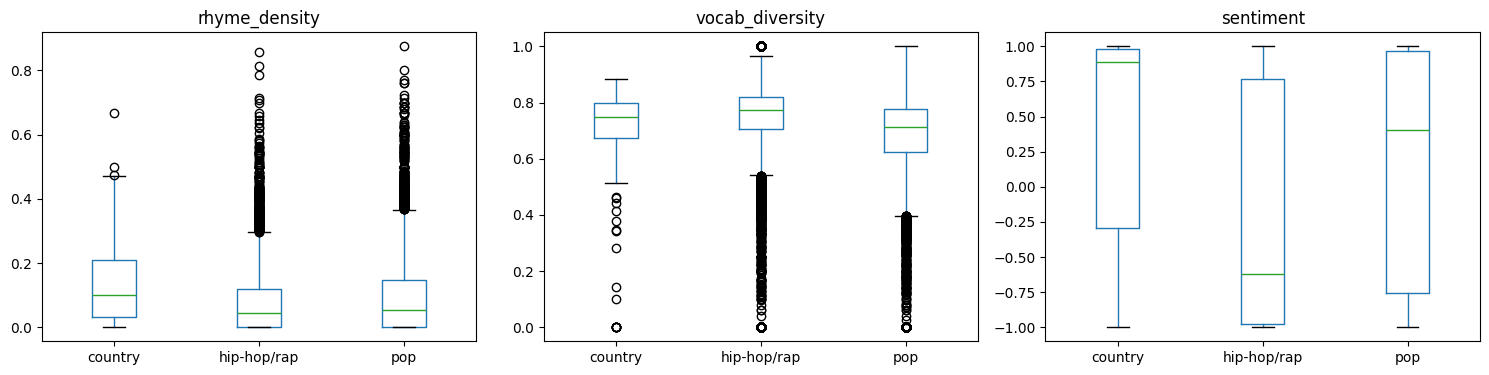

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(ax, ["rhyme_density", "vocab_diversity", "sentiment"]):
    feat_df.boxplot(column=f, by="genre", ax=a, grid=False)
    a.set_title(f); a.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

## Do lyric features add value?

In [23]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

d = feat_df.dropna(subset=FEATURES + ["log_views", "year"]).reset_index(drop=True)
genre_dummies = pd.get_dummies(d["genre"], prefix="g").astype(float)
X_base = pd.concat([d[["year"]], genre_dummies], axis=1)
X_full = pd.concat([X_base, d[FEATURES]], axis=1)
y = d["log_views"].values
groups = d["artist"].values

def cv_eval(X, name, n_splits=5):
    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        m = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE)
        m.fit(X.iloc[tr], y[tr])
        oof[te] = m.predict(X.iloc[te])
    return {"model": name, "R2": r2_score(y, oof), "MAE": mean_absolute_error(y, oof),
            "Spearman": spearmanr(y, oof)[0]}, oof

res_base, oof_base = cv_eval(X_base, "baseline (genre + year)")
res_full, oof_full = cv_eval(X_full, "baseline + lyric features")
results = pd.DataFrame([res_base, res_full]).set_index("model").round(3)
display(results)

,R2,MAE,Spearman
model,,,
baseline (genre + year),0.082,1.643,0.294
baseline + lyric features,0.145,1.575,0.381


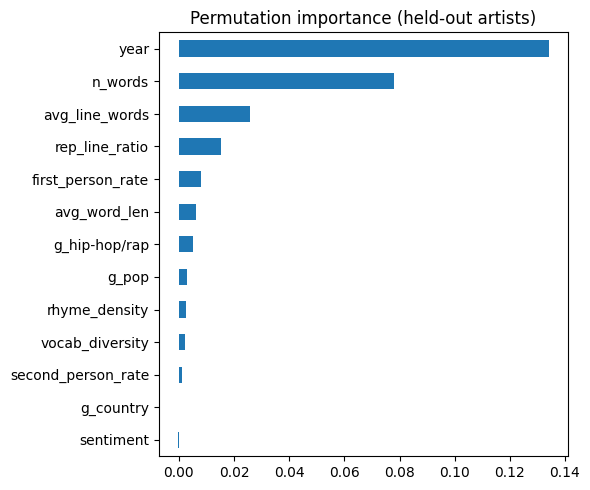

In [24]:
# which features matter?
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(X_full, y, groups))
m = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE)
m.fit(X_full.iloc[tr], y[tr])
pi = permutation_importance(m, X_full.iloc[te], y[te], n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X_full.columns).sort_values()
imp.plot.barh(figsize=(6, 5), title="Permutation importance (held-out artists)")
plt.tight_layout(); plt.show()